# Práctica 3 · Etapa 2 — Datos de la estación 2038: auditoría, limpieza e ingeniería de características

**3201 Modelos Inteligentes de Aprendizaje / 529 Redes Neuronales Modulares** · Maestría y Doctorado en Ciencias e Ingeniería (MyDCI) · Facultad de Ingeniería, Arquitectura y Diseño ·
Universidad Autónoma de Baja California · Ciclo 2026-2 · Versión 6

**Profesores:** Dr. Everardo Inzunza González · Dr. Enrique Efrén García Guerrero · Dr. Oscar Adrián Aguirre Castro

**Fase 2 de la sesión** · presupuesto: **20 min**

---

La Etapa 1 reprodujo el flujo del video con una serie horaria muy regular. Ahora el problema es más realista: **precipitación mensual** de una estación climatológica, con años ausentes, meses faltantes, muchos ceros y picos extremos. Antes de entrenar nada se **audita** la serie (lo que no se mide no se puede afirmar), se decide cómo tratar lo que falta sin usar información del futuro, se convierte la serie en una **tabla supervisada** (cada fila guarda el pasado, X, y el valor a predecir, y) y se **reserva el bloque de prueba** antes de mirar autocorrelaciones o correlaciones: todo lo que oriente una decisión de modelado se calcula sólo con los datos de desarrollo.

| Necesita | Produce |
|---|---|
| `datos/DATOS_MENSUALES_EST_2038.xlsx` | Tabla D · figuras F5 y F6 · `artefactos/serie_2038_limpia.csv` y `artefactos/caracteristicas_2038.csv` |

**Cómo leer este cuaderno.** Cada bloque abre con una celda de texto que explica *qué* se hace y *por qué*. Dentro del
código, el comentario a la derecha de cada instrucción dice para qué sirve esa línea. Las salidas marcadas con
**`← Anote`** son las que usted copia en la tabla indicada del manual; el resto sólo se ejecuta y se observa.
Ejecute las celdas **en orden**; si cambia algo, vuelva a ejecutar desde esa celda hacia abajo.

---
## Bloque 0 · Puesta en marcha

Esta celda se ejecuta **siempre primero**, en cualquier entorno. Detecta si está en Google Colab, en el JupyterHub del
laboratorio o en un Jupyter local; localiza la carpeta de la práctica (`P3_SeriesTiempo_v6`, la que descargó de
Classroom); crea `resultados/` con sus subcarpetas sin borrar nada; instala sólo lo que falte; fija la semilla e imprime
las versiones con que se ejecutó. Reproducir un resultado empieza por saber con qué se obtuvo.

> **En Colab**, cada cuaderno corre en su propia máquina virtual: los archivos que un cuaderno guarda sólo los ve el
> siguiente si viven en **Google Drive**. Por eso la carpeta de la práctica se sube a *Mi unidad* y esta celda la monta.

In [25]:
# ── Bloque 0 · Puesta en marcha (Etapa 2) ─────────────────────────────────────────────
import sys, os, json, time, hashlib, warnings, subprocess, importlib  # utilidades estándar de Python
from pathlib import Path                                   # rutas que funcionan igual en Windows, Linux y Colab
T0 = time.perf_counter()                                   # cronómetro de este cuaderno
warnings.filterwarnings("ignore", category=FutureWarning)  # oculta sólo avisos de versiones futuras

try:
    import google.colab                                    # este módulo sólo existe dentro de Google Colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

CARPETA_PRACTICA = "P3_SeriesTiempo_v6"                    # la carpeta que descargó de Classroom
if EN_COLAB:
    from google.colab import drive                         # acceso a Google Drive desde Colab
    drive.mount("/content/drive")                          # la primera vez pide autorización
    RAIZ_DRIVE = Path("/content/drive/MyDrive")            # «Mi unidad»
    candidatas = [RAIZ_DRIVE / CARPETA_PRACTICA, RAIZ_DRIVE / "Colab Notebooks" / CARPETA_PRACTICA]
    candidatas += sorted(RAIZ_DRIVE.glob(f"*/{CARPETA_PRACTICA}"))  # también un nivel más abajo
else:
    aqui = Path.cwd().resolve()                            # carpeta desde donde se abrió el cuaderno
    candidatas = [aqui, *aqui.parents][:4]                 # el cuaderno vive en notebooks/: se busca hacia arriba
    candidatas += [p / CARPETA_PRACTICA for p in candidatas]
BASE = next((c for c in candidatas if (c / "datos").is_dir() and (c / "notebooks").is_dir()), None)
if BASE is None:
    raise FileNotFoundError("No encuentro la carpeta de la práctica (con datos/ y notebooks/). "
                            "Revise la Sección 4.3 del manual: en Colab súbala completa a «Mi unidad».")
DATOS, RES = BASE / "datos", BASE / "resultados"           # entradas y salidas de la práctica
FIG, TAB, ART = RES / "figuras", RES / "tablas", RES / "artefactos"  # figuras · tablas · archivos intermedios
for carpeta in (FIG, TAB, ART):
    carpeta.mkdir(parents=True, exist_ok=True)             # se crean si faltan; nunca se borra nada

# Bibliotecas: se instala sólo lo que falte (en Colab casi todo viene preinstalado).
NECESARIAS = {"numpy": "numpy", "pandas": "pandas", "sklearn": "scikit-learn", "xgboost": "xgboost",
               "matplotlib": "matplotlib", "seaborn": "seaborn", "statsmodels": "statsmodels",
               "openpyxl": "openpyxl", "scipy": "scipy"}
for modulo, paquete in NECESARIAS.items():
    try:
        importlib.import_module(modulo)                    # ¿ya está instalado?
    except ImportError:
        print("Instalando", paquete, "…")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paquete], check=True)

import numpy as np                                         # cálculo numérico con arreglos
import pandas as pd                                        # tablas de datos indexadas por fecha
import matplotlib                                          # motor de gráficas
import matplotlib.pyplot as plt                            # interfaz de gráficas
import sklearn, xgboost as xgb                             # scikit-learn y XGBoost
import seaborn, statsmodels, scipy                         # sólo para registrar sus versiones aquí
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf  # autocorrelación

def _ver(v):
    return tuple(int("".join(ch for ch in p if ch.isdigit()) or 0) for p in v.split(".")[:2])
assert _ver(sklearn.__version__) >= (1, 4), "Se necesita scikit-learn ≥ 1.4 (root_mean_squared_error)."
assert _ver(xgb.__version__) >= (2, 0), "Se necesita XGBoost ≥ 2.0 (early_stopping_rounds en el constructor)."

SEMILLA = 42                                               # una sola semilla para toda la práctica
np.random.seed(SEMILLA)                                    # fija el azar de numpy
pd.set_option("display.width", 160)                        # tablas anchas sin cortes de renglón
pd.set_option("display.max_columns", 30)
COLORES = {"real": "#15241E", "XGBoost": "#17795C", "SVR": "#D9A21B", "Random Forest": "#9E2B25",
            "Ingenuo": "#9AA7A1", "Ingenuo estacional": "#5E6E67", "Climatología": "#165542"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})  # estilo uniforme de las figuras

def guardar(fig, nombre):
    """Guarda la figura en resultados/figuras/ (PNG, 150 dpi) para insertarla en el manual."""
    ruta = FIG / f"{nombre}.png"
    fig.savefig(ruta, dpi=150, bbox_inches="tight")
    print("Figura guardada →", ruta.relative_to(BASE))

def _serializable(v):
    """Convierte tipos de numpy y pandas a tipos de Python; los no finitos (NaN, ±inf) quedan como None."""
    if isinstance(v, dict):
        return {str(k): _serializable(x) for k, x in v.items()}
    if isinstance(v, (list, tuple)):
        return [_serializable(x) for x in v]
    if isinstance(v, (bool, np.bool_)):
        return bool(v)
    if isinstance(v, (int, np.integer)):
        return int(v)
    if isinstance(v, (float, np.floating)):
        return float(v) if np.isfinite(v) else None
    if isinstance(v, pd.Timestamp):
        return v.isoformat()
    return v

def registrar(clave, valor):
    """Añade un resultado a resultados/registro_P3.json (se acumula entre cuadernos; JSON estricto, sin NaN)."""
    ruta = RES / "registro_P3.json"
    reg = json.loads(ruta.read_text(encoding="utf-8")) if ruta.exists() else {}
    reg[clave] = _serializable(valor)
    ruta.write_text(json.dumps(reg, ensure_ascii=False, indent=1, allow_nan=False), encoding="utf-8")

def md5(ruta):
    return hashlib.md5(Path(ruta).read_bytes()).hexdigest()  # huella del archivo

if EN_COLAB:
    ENTORNO = "Google Colab"
elif "JUPYTERHUB_USER" in os.environ:
    ENTORNO = "JupyterHub"                                 # sesión abierta en el JupyterHub del laboratorio
elif "ai_env" in sys.executable:
    ENTORNO = "Kernel ai_env del laboratorio"              # el mismo kernel, fuera de una sesión del Hub
else:
    ENTORNO = "Jupyter local"
VERSIONES = {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__,
              "scikit-learn": sklearn.__version__, "xgboost": xgb.__version__, "matplotlib": matplotlib.__version__,
              "seaborn": seaborn.__version__, "statsmodels": statsmodels.__version__, "scipy": scipy.__version__}
registrar("etapa2_entorno", {"entorno": ENTORNO, **VERSIONES})
print("Entorno        :", ENTORNO)                         # ← Anote (Tabla A)
print("Carpeta base   :", BASE)
for k, v in VERSIONES.items():
    print(f"{k:<15}:", v)                                  # ← Anote (Tabla A): Python, scikit-learn, XGBoost y pandas

Entorno        : Jupyter local
Carpeta base   : C:\Users\Diana\git\Course_RedesNeuronales_2026\PR3_TimeSeries\P3_SeriesTiempo_v6
python         : 3.12.15
numpy          : 2.5.4
pandas         : 3.1.0
scikit-learn   : 1.9.1
xgboost        : 3.4.1
matplotlib     : 3.11.2
seaborn        : 0.13.2
statsmodels    : 0.15.0
scipy          : 1.18.1


---
## 2.1 Carga y conversión de formato ancho a formato largo

El archivo trae **una fila por año y una columna por mes** (formato *ancho*). Un modelo de series de tiempo necesita
lo contrario: **una fila por instante**, ordenada en el tiempo (formato *largo*). `melt` hace esa conversión y
`pd.to_datetime` construye la fecha del primer día de cada mes, que será el índice de la serie.

In [8]:
ARCHIVO = DATOS / "DATOS_MENSUALES_EST_2038.xlsx"           # precipitación mensual de la estación 2038
print("MD5 del archivo:", md5(ARCHIVO))                     # ← Anote (Tabla D): debe ser 79db93f4acdb00dee34cdd85c70d62ad
ancho = pd.read_excel(ARCHIVO, sheet_name=0)                # requiere openpyxl (lo instala el Bloque 0)
print("Forma del archivo (años × columnas):", ancho.shape)  # ← Anote (Tabla D)
ancho.head()                                                # vistazo a las primeras filas

MD5 del archivo: 79db93f4acdb00dee34cdd85c70d62ad
Forma del archivo (años × columnas): (95, 13)


,AÑO,ENE,FEB,MAR,ABR,MAY,JUN,JUL,AGO,SEP,OCT,NOV,DIC
0,1929,40.6,28.7,34.2,21.90,0.0,0.0,0.0,0.0,0.9,0.0,0.0,0.0
1,1930,NaN,1.0,8.3,31.01,NaN,NaN,8.0,0.0,0.0,1.9,NaN,NaN
2,1932,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,79.7
3,1933,130.0,0.0,0.0,21.40,3.1,0.0,0.0,0.0,0.0,0.3,0.0,23.0
4,1934,0.4,2.1,1.1,19.90,0.0,0.7,0.1,0.3,0.6,2.1,2.4,7.4


In [6]:
MESES = ["ENE", "FEB", "MAR", "ABR", "MAY", "JUN", "JUL", "AGO", "SEP", "OCT", "NOV", "DIC"]
largo = ancho.melt(id_vars="AÑO", value_vars=MESES,         # de 12 columnas a una sola columna de valores
                   var_name="MES", value_name="PRECIP_mm")
largo["FECHA"] = pd.to_datetime(dict(year=largo["AÑO"],     # fecha = primer día del mes
                                     month=largo["MES"].map(MESES.index) + 1, day=1))
bruta = largo.set_index("FECHA")["PRECIP_mm"].sort_index()  # serie ordenada en el tiempo

años = ancho["AÑO"].astype(int)                             # años presentes en el archivo
ausentes = sorted(set(range(años.min(), años.max() + 1)) - set(años))  # años que faltan por completo
print(f"Años en el archivo: {len(años)} ({años.min()}–{años.max()})")  # ← Anote (Tabla D)
print("Años ausentes      :", ausentes)                     # ← Anote (Tabla D)
print("Meses con dato     :", int(bruta.notna().sum()), "de", len(bruta))

Años en el archivo: 95 (1929–2026)
Años ausentes      : [1931, 1937, 1938]
Meses con dato     : 1109 de 1140


---
## 2.2 Periodo de estudio y datos faltantes

Un modelo con rezagos necesita una serie **sin huecos de años enteros**: `y(t−12)` no existe si falta el año anterior.
La decisión de esta práctica es usar el tramo continuo más largo, que empieza el año siguiente al último año ausente y
termina en el último mes observado. `asfreq("MS")` obliga a que exista una fila por mes (*Month Start*): si algún mes
no venía en el archivo, aparece como `NaN` y queda a la vista en vez de esconderse.

In [7]:
inicio = max(ausentes) + 1 if ausentes else años.min()  # primer año del tramo continuo
fin = bruta.last_valid_index()                          # último mes con dato observado
serie = bruta.loc[f"{inicio}-01-01":fin].asfreq("MS")   # una fila por mes, sin saltos de fecha
faltan = serie[serie.isna()]                            # meses sin dato dentro del periodo
print("Periodo de estudio :", serie.index[0].strftime("%Y-%m"), "a", serie.index[-1].strftime("%Y-%m"))  # ← Anote (Tabla D)
print("Meses en el periodo:", len(serie))               # ← Anote (Tabla D)
print("Meses faltantes    :", len(faltan), "→", [f.strftime("%Y-%m") for f in faltan.index])  # ← Anote (Tabla D)

Periodo de estudio : 1939-01 a 2026-04
Meses en el periodo: 1048
Meses faltantes    : 5 → ['1949-03', '1949-04', '1949-05', '1986-08', '2014-04']


---
## 2.3 Auditoría de la serie: ceros, resolución del registro y valores extremos

La precipitación de un clima con lluvias de invierno es **intermitente**: muchos meses secos y unos pocos con
tormentas. Esto condiciona todo lo que sigue: el MAPE no estará definido cuando el valor real sea cero, el R² será
modesto y los errores grandes se concentrarán en los meses de tormenta. Medirlo ahora evita sorpresas después. Esta
auditoría describe el **archivo completo** —es control de calidad de los datos, no una decisión de modelado—; las
decisiones de modelado (rezagos, correlaciones) vienen después y usan sólo los datos de desarrollo.

In [12]:
obs = serie.dropna()                                       # sólo los meses observados
print(f"Meses con precipitación 0: {(obs == 0).sum()} ({(obs == 0).mean():.1%})")  # ← Anote (Tabla D)
print(f"Máximo: {obs.max():.1f} mm en {obs.idxmax():%Y-%m}")  # ← Anote (Tabla D)
print(f"Media: {obs.mean():.2f} mm · mediana: {obs.median():.2f} mm · desv. estándar: {obs.std():.2f} mm")

por_mes = pd.DataFrame({                                   # perfil estacional: un renglón por mes calendario
    "media_mm": obs.groupby(obs.index.month).mean(),
    "mediana_mm": obs.groupby(obs.index.month).median(),
    "q3_mm": obs.groupby(obs.index.month).quantile(0.75),  # tercer cuartil: lo usa la regla de Tukey
    "fraccion_ceros": obs.groupby(obs.index.month).apply(lambda v: (v == 0).mean()),
}).round(2)
por_mes.index = MESES
por_mes.T                                                  # ¿qué meses son secos y cuáles lluviosos?

Meses con precipitación 0: 289 (27.7%)
Máximo: 315.2 mm en 1993-01
Media: 18.84 mm · mediana: 3.70 mm · desv. estándar: 32.02 mm


,ENE,FEB,MAR,ABR,MAY,JUN,JUL,AGO,SEP,OCT,NOV,DIC
media_mm,43.64,43.41,39.22,16.35,4.56,0.59,0.81,2.31,4.00,10.00,23.07,37.12
mediana_mm,27.40,28.31,27.70,8.60,0.55,0.00,0.00,0.00,0.01,1.40,13.83,25.20
q3_mm,69.82,66.94,57.70,25.20,4.68,0.50,0.50,0.20,3.25,9.10,28.50,52.65
fraccion_ceros,0.02,0.02,0.03,0.08,0.31,0.63,0.68,0.67,0.47,0.25,0.13,0.02


In [10]:
# Resolución del registro: ¿cuántos decimales trae cada dato? Un cambio de resolución a lo largo del tiempo puede
# deberse al instrumento, a la captura o a la forma en que se construyó el archivo de trabajo; conviene saberlo
# antes de modelar y contrastarlo con el registro oficial (Crítica de fuentes, Anexo P).
decimales = obs.map(lambda v: len(f"{v:.2f}".rstrip("0").split(".")[1]) if v != int(v) else 0)  # 0, 1 o 2 decimales
tabla_dec = decimales.groupby((obs.index.year // 10) * 10).value_counts().unstack(fill_value=0)  # conteo por década
antes, desde = obs.index.year < 2000, obs.index.year >= 2000  # dos épocas del registro
prop_dos_antes, prop_dos_desde = (decimales[antes] == 2).mean(), (decimales[desde] == 2).mean()
print("Valores con dos decimales:", int((decimales == 2).sum()))  # ← Anote (Tabla D)
print(f"Proporción con dos decimales: {prop_dos_antes:.1%} antes de 2000 · {prop_dos_desde:.1%} desde 2000")  # ← Anote (Tabla D)
tabla_dec  # filas = década · columnas = número de decimales

Valores con dos decimales: 151
Proporción con dos decimales: 4.1% antes de 2000 · 38.4% desde 2000


PRECIP_mm,0,1,2
FECHA,,,
1930,3,9,0
1940,93,21,3
1950,56,62,2
1960,43,72,5
1970,41,73,6
1980,36,79,4
1990,37,73,10
2000,35,37,48
2010,30,45,44


In [11]:
# Valores extremos con la regla de Tukey (1.5 × rango intercuartílico) aplicada POR MES CALENDARIO:
# 30 mm es poco para enero y muchísimo para julio.
def es_extremo(v):
    q1, q3 = v.quantile([0.25, 0.75])                       # cuartiles del mes calendario
    return v > q3 + 1.5 * (q3 - q1)                         # verdadero si supera el límite superior

extremo = obs.groupby(obs.index.month, group_keys=False).apply(es_extremo)  # una bandera por mes observado
print("Meses marcados como extremos:", int(extremo.sum()))  # ← Anote (Tabla D)
por_mes_ext = extremo.groupby(extremo.index.month).sum().astype(int)  # ¿en qué meses caen?
por_mes_ext.index = MESES
print("Extremos por mes calendario:", por_mes_ext.to_dict())  # ← Anote (Tabla D): los meses con más marcas
obs.sort_values(ascending=False).head(5).round(1).to_frame("Los 5 meses más lluviosos (mm)")

Meses marcados como extremos: 96
Extremos por mes calendario: {'ENE': 2, 'FEB': 2, 'MAR': 2, 'ABR': 3, 'MAY': 8, 'JUN': 13, 'JUL': 11, 'AGO': 20, 'SEP': 11, 'OCT': 11, 'NOV': 8, 'DIC': 5}


,Los 5 meses más lluviosos (mm)
FECHA,
1993-01-01,315.2
1998-02-01,244.1
2004-10-01,207.9
1983-03-01,169.8
1980-01-01,166.2


> **Lea con cuidado la regla de Tukey en una serie intermitente.** Compare el conteo de extremos por mes con la fila
> `q3_mm` de la tabla anterior. En los meses cuya mediana es cero y cuyo tercer cuartil es muy pequeño, casi
> **cualquier** lluvia queda por encima del límite y se marca como «extrema»; si es su caso, las marcas se concentrarán
> en los meses secos y no en los meses de tormentas. La regla no está mal programada: supone una distribución sin una
> gran masa de ceros, y en una serie intermitente esa suposición falla.

> **Decisión metodológica 1 · ¿Se eliminan los extremos?** En esta práctica **no**: una tormenta de varios cientos de
> milímetros es un evento físico plausible, no un error de captura, y quitarla dejaría al modelo ciego justo ante lo
> que más importa pronosticar. La decisión tiene un costo: el RMSE quedará dominado por pocos meses. **En su reporte,
> justifique por escrito** si conservaría o trataría los extremos en *su* problema, y qué métrica usaría para que la
> decisión no quede escondida.

---
## 2.4 Imputación sin fuga de información

Quedan unos pocos meses sin dato. La versión anterior de la práctica los rellenaba con la mediana de ese mes calendario
calculada **con toda la serie**, lo que usa información de años futuros para rellenar el pasado. Aquí se usa una
**imputación causal**: cada hueco se rellena con la mediana de ese mismo mes calendario **en los años anteriores**.
Además se conserva una bandera `imputado`, porque un mes rellenado puede servir como rezago, pero **no** debe usarse
como valor real contra el que se evalúa un pronóstico.

In [13]:
mediana_previa = serie.groupby(serie.index.month).transform(  # para cada mes calendario…
    lambda v: v.expanding().median().shift(1))  # …la mediana de los años ANTERIORES (shift evita usar el propio año)
imputado = serie.isna()                         # bandera: True donde no había dato
limpia = serie.fillna(mediana_previa)           # relleno causal
assert limpia.notna().all(), "Quedó algún hueco sin rellenar"  # verificación explícita
print("Meses imputados:", int(imputado.sum()))  # ← Anote (Tabla D)
pd.DataFrame({"valor_imputado_mm": limpia[imputado].round(2)})  # qué valor recibió cada hueco

Meses imputados: 5


,valor_imputado_mm
FECHA,
1949-03-01,24.50
1949-04-01,6.40
1949-05-01,0.00
1986-08-01,0.00
2014-04-01,10.76


---
## 2.5 De la serie a una tabla supervisada (ingeniería de características)

Los regresores de scikit-learn **no saben que los datos están ordenados en el tiempo**: reciben una fila y devuelven un
número. Para que pronostiquen, cada fila debe traer escrito su pasado:

| Tipo | Columnas | Qué captura |
|---|---|---|
| Rezagos (*lags*) | `lag_1`, `lag_2`, `lag_3`, `lag_12` | la memoria corta y el mismo mes del año anterior |
| Estadísticos móviles | `media_3`, `media_12` | el nivel reciente, suavizado (calculados **sólo con el pasado**) |
| Calendario cíclico | `mes_sin`, `mes_cos` | la posición en el año sin el salto artificial entre diciembre (12) y enero (1) |

La regla de oro: **toda columna de la fila *t* se calcula con información disponible antes de *t***. Por eso las
medias móviles se calculan después de `shift(1)`. Los rezagos se eligen aquí por razones físicas (memoria corta y
ciclo anual); la autocorrelación de la sección 2.7 dirá, con los datos de desarrollo, si la elección se sostiene.

In [14]:
def crear_caracteristicas(s):
    """Convierte una serie mensual en una tabla X con rezagos, medias móviles y calendario cíclico."""
    X = pd.DataFrame(index=s.index)
    X["mes_sin"] = np.sin(2 * np.pi * s.index.month / 12)   # posición en el ciclo anual (seno)…
    X["mes_cos"] = np.cos(2 * np.pi * s.index.month / 12)   # …y coseno: diciembre queda junto a enero
    for k in (1, 2, 3, 12):
        X[f"lag_{k}"] = s.shift(k)                          # valor de hace k meses (la rejilla es regular: k pasos = k meses)
    X["media_3"] = s.shift(1).rolling(3).mean()             # media de t−1, t−2, t−3 (shift ANTES de rolling)
    X["media_12"] = s.shift(1).rolling(12).mean()           # media de los 12 meses previos
    return X

X_todo = crear_caracteristicas(limpia)
tabla = X_todo.assign(y=limpia, imputado=imputado).dropna()  # las 12 primeras filas no tienen lag_12
n_antes = len(tabla)
tabla = tabla[~tabla["imputado"]].drop(columns="imputado")  # no se evalúa contra un mes inventado
print("Filas con todas sus características:", n_antes)      # ← Anote (Tabla D)
print("Filas descartadas por objetivo imputado:", n_antes - len(tabla))  # ← Anote (Tabla D)
print("Tabla supervisada final:", tabla.shape)              # ← Anote (Tabla D: sólo el número de filas); forma = filas × (características + y)
tabla.head()

Filas con todas sus características: 1036
Filas descartadas por objetivo imputado: 5
Tabla supervisada final: (1031, 9)


,mes_sin,mes_cos,lag_1,lag_2,lag_3,lag_12,media_3,media_12,y
FECHA,,,,,,,,,
1940-01-01,0.500000,8.660254e-01,1.2,2.4,1.7,5.4,1.766667,2.400000,3.9
1940-02-01,0.866025,5.000000e-01,3.9,1.2,2.4,4.7,2.500000,2.275000,5.3
1940-03-01,1.000000,6.123234e-17,5.3,3.9,1.2,2.2,3.466667,2.325000,2.5
1940-04-01,0.866025,-5.000000e-01,2.5,5.3,3.9,0.3,3.900000,2.350000,0.8
1940-05-01,0.500000,-8.660254e-01,0.8,2.5,5.3,0.6,2.866667,2.391667,0.0


---
## 2.6 Reserva del bloque de prueba

La Etapa 3 partirá esta tabla en entrenamiento, validación y prueba (70/15/15, sin barajar). El bloque de prueba se
mira **una sola vez**, en la Etapa 5; todo lo que oriente una decisión de modelado antes de eso —qué rezagos valen,
qué características correlacionan con la lluvia, si una media móvil tiene fuga— debe calcularse sin él. Por eso la
misma partición se aplica **ya aquí**, sólo para conocer la última fecha del desarrollo (entrenamiento + validación);
de aquí en adelante este cuaderno trabaja con `desarrollo` y deja la prueba intacta. La figura F5 muestra la serie
completa, con el bloque reservado en gris.

In [15]:
from sklearn.model_selection import train_test_split
X_entr, X_tmp, _, y_tmp = train_test_split(tabla.drop(columns="y"), tabla["y"], test_size=0.30, shuffle=False)  # 70 % | 30 %
X_valid, X_prueba, _, _ = train_test_split(X_tmp, y_tmp, test_size=0.50, shuffle=False)  # 15 % | 15 %
fin_desarrollo = X_valid.index[-1]       # último mes del desarrollo (fin de la validación)
desarrollo = tabla.loc[:fin_desarrollo]  # filas de entrenamiento + validación
limpia_des, obs_des = limpia.loc[:fin_desarrollo], obs.loc[:fin_desarrollo]  # la serie, hasta esa fecha
print("Desarrollo hasta:", f"{fin_desarrollo:%Y-%m}", "·", len(desarrollo), "filas · prueba reservada:",
      len(X_prueba), "filas desde", f"{X_prueba.index[0]:%Y-%m}")  # ← Anote (Tabla D)

Desarrollo hasta: 2013-04 · 876 filas · prueba reservada: 155 filas desde 2013-05


Figura guardada → resultados\figuras\F05_est2038_serie_y_climatologia.png


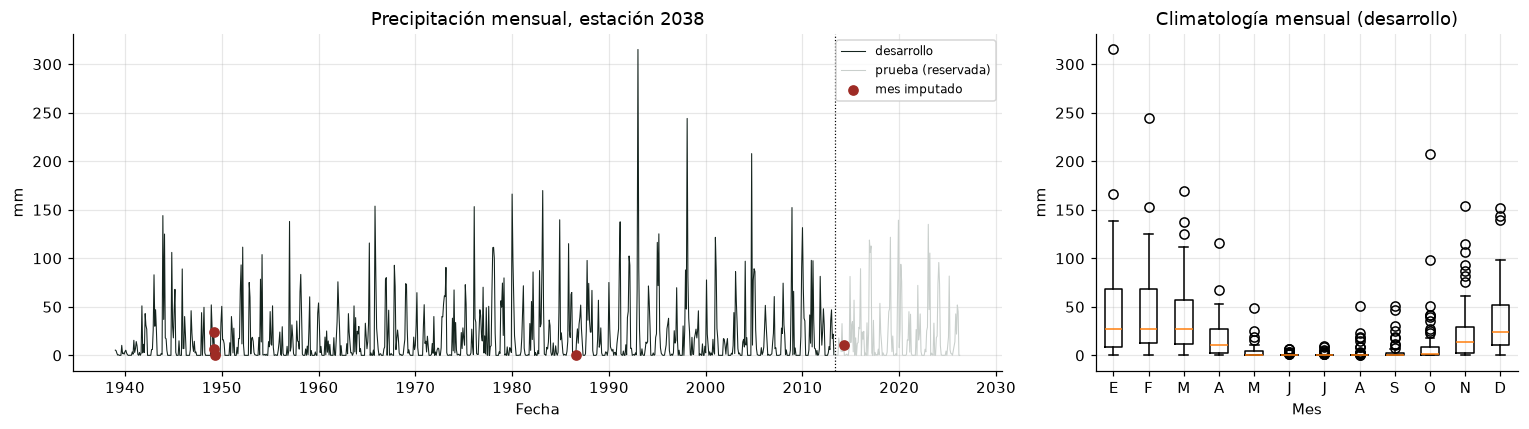

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2.2, 1]})
ax[0].plot(limpia_des.index, limpia_des.values, lw=0.7, color=COLORES["real"], label="desarrollo")  # en color
prueba_serie = limpia.loc[X_prueba.index[0]:]
ax[0].plot(prueba_serie.index, prueba_serie.values, lw=0.7, color="#C9CFCC", label="prueba (reservada)")  # en gris
ax[0].scatter(limpia.index[imputado], limpia[imputado], color=COLORES["Random Forest"], zorder=3,
              label="mes imputado")               # dónde se rellenó
ax[0].axvline(X_prueba.index[0], color="k", ls=":", lw=0.8)  # inicio del bloque reservado
ax[0].set(title="Precipitación mensual, estación 2038", xlabel="Fecha", ylabel="mm")
ax[0].legend(fontsize=8)
datos_mes = [obs_des[obs_des.index.month == m].values for m in range(1, 13)]  # un grupo por mes calendario (desarrollo)
ax[1].boxplot(datos_mes, showfliers=True)         # distribución de cada mes
ax[1].set_xticks(range(1, 13), [m[0] for m in MESES])
ax[1].set(title="Climatología mensual (desarrollo)", xlabel="Mes", ylabel="mm")
fig.tight_layout()
guardar(fig, "F05_est2038_serie_y_climatologia")  # → Figura F5 del manual
plt.show()

---
## 2.7 Autocorrelación y correlaciones, con los datos de desarrollo

La **autocorrelación** mide qué tanto se parece la serie a sí misma desplazada *k* meses. Si la estacionalidad es anual,
la ACF debe repuntar en los rezagos 12, 24 y 36; la PACF descuenta los rezagos intermedios. Después se mide la
correlación lineal de cada característica con `y`. Las dos cosas se calculan **sólo con el desarrollo**: son
diagnósticos que orientan el modelado y no deben ver la prueba.

Figura guardada → resultados\figuras\F06_est2038_acf_pacf.png


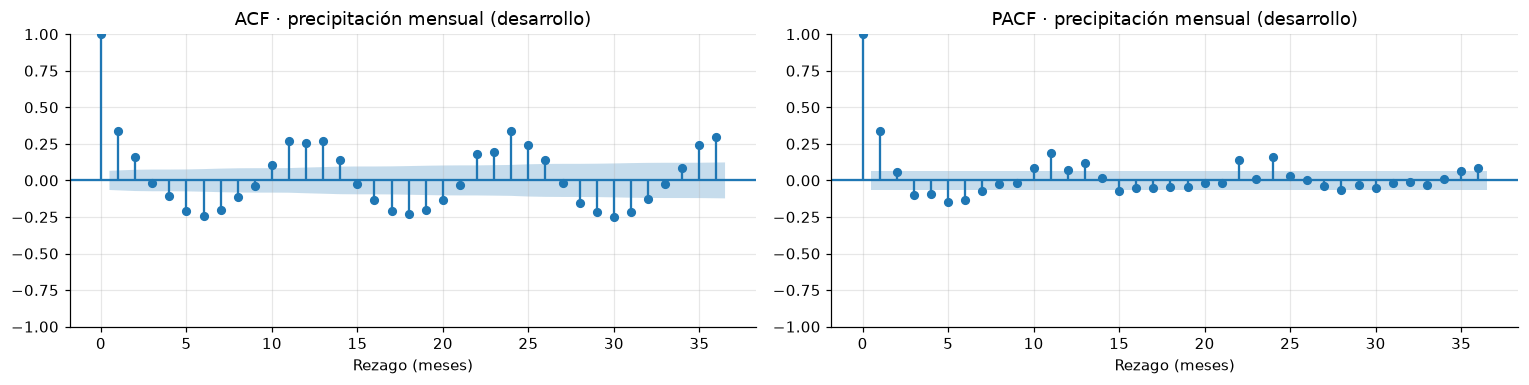

ACF rezago 1 = 0.337 · ACF rezago 12 = 0.257


In [21]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
plot_acf(limpia_des, lags=36, ax=ax[0])                 # autocorrelación hasta 3 años
plot_pacf(limpia_des, lags=36, ax=ax[1], method="ywm")  # autocorrelación parcial (descuenta rezagos intermedios)
ax[0].set(title="ACF · precipitación mensual (desarrollo)", xlabel="Rezago (meses)")
ax[1].set(title="PACF · precipitación mensual (desarrollo)", xlabel="Rezago (meses)")
fig.tight_layout()
guardar(fig, "F06_est2038_acf_pacf")                    # → Figura F6 del manual
plt.show()
from statsmodels.tsa.stattools import acf
r = acf(limpia_des, nlags=12)                           # valores numéricos de la ACF
print(f"ACF rezago 1 = {r[1]:.3f} · ACF rezago 12 = {r[12]:.3f}")  # ← Anote (Tabla D)

In [18]:
corr = desarrollo.corr()["y"].drop("y").sort_values(key=abs, ascending=False)  # correlación lineal de cada X con y
print(corr.round(3).to_string())  # ← Anote (Tabla D): las dos más correlacionadas

mes_cos     0.391
lag_1       0.335
mes_sin     0.324
lag_12      0.257
media_3     0.220
lag_2       0.160
media_12    0.050
lag_3      -0.021


---
## 2.8 Experimento rápido: cómo se ve una fuga de información

¿Qué pasa si se olvida el `shift(1)` y la media móvil incluye el propio valor `y(t)`? La columna «sabe» la respuesta.
La celda entrena el mismo bosque aleatorio dos veces —con la media correcta y con la media con fuga— **dentro del
desarrollo**, con una partición temporal interna 85/15, y compara el R² en el tramo final. La prueba reservada no
interviene. **Un resultado demasiado bueno es la primera señal de alarma de una fuga**, no un motivo de celebración.

In [22]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

con_fuga = desarrollo.copy()
con_fuga["media_3"] = limpia.rolling(3).mean().reindex(con_fuga.index)  # ¡incluye y(t)! (falta shift(1))
corte = int(len(desarrollo) * 0.85)  # partición temporal interna: el 15 % final del desarrollo evalúa
r2 = {}
for nombre, t in [("correcta (con shift)", desarrollo), ("con fuga (sin shift)", con_fuga)]:
    Xa, ya = t.drop(columns="y"), t["y"]
    m = RandomForestRegressor(n_estimators=200, random_state=SEMILLA, n_jobs=-1).fit(Xa[:corte], ya[:corte])
    r2[nombre] = r2_score(ya[corte:], m.predict(Xa[corte:]))  # R² en el tramo final del desarrollo
    print(f"R² en el tramo final del desarrollo, media móvil {nombre}: {r2[nombre]:.3f}")  # ← Anote (Tabla D)
print(f"Tramo evaluado: {ya.index[corte]:%Y-%m} a {ya.index[-1]:%Y-%m} ({len(ya) - corte} meses)")

R² en el tramo final del desarrollo, media móvil correcta (con shift): 0.114
R² en el tramo final del desarrollo, media móvil con fuga (sin shift): 0.844
Tramo evaluado: 2002-05 a 2013-04 (132 meses)


---
## 2.9 Guardar los artefactos para la Etapa 3

Se guardan dos archivos en `resultados/artefactos/`: la serie limpia con su bandera de imputación y la tabla
supervisada **completa** (la Etapa 3 vuelve a hacer la partición y la guarda fecha por fecha). Si cambia algo aquí,
vuelva a ejecutar las etapas siguientes.

In [23]:
pd.DataFrame({"PRECIP_mm": limpia, "imputado": imputado}).to_csv(ART / "serie_2038_limpia.csv", index_label="FECHA")
tabla.to_csv(ART / "caracteristicas_2038.csv", index_label="FECHA")  # X + y, una fila por mes
registrar("etapa2", {
    "md5": md5(ARCHIVO), "forma_archivo": list(ancho.shape), "anios": int(len(años)), "anios_ausentes": ausentes,
    "periodo": [serie.index[0].strftime("%Y-%m"), serie.index[-1].strftime("%Y-%m")], "meses": int(len(serie)),
    "faltantes": [f.strftime("%Y-%m") for f in faltan.index], "ceros": int((obs == 0).sum()),
    "fraccion_ceros": round(float((obs == 0).mean()), 4), "maximo_mm": float(obs.max()),
    "fecha_maximo": obs.idxmax().strftime("%Y-%m"),
    "media_mm": round(float(obs.mean()), 4), "mediana_mm": round(float(obs.median()), 4),
    "por_mes": por_mes.to_dict(orient="index"),
    "extremos_tukey": int(extremo.sum()), "extremos_por_mes": por_mes_ext.to_dict(),
    "dos_decimales": int((decimales == 2).sum()),
    "prop_dos_decimales_antes_2000": round(float(prop_dos_antes), 4),
    "prop_dos_decimales_desde_2000": round(float(prop_dos_desde), 4),
    "imputados": int(imputado.sum()),
    "valores_imputados_mm": {f"{t:%Y-%m}": round(float(v), 2) for t, v in limpia[imputado].items()},
    "filas_con_caracteristicas": int(n_antes), "filas_descartadas_imputadas": int(n_antes - len(tabla)),
    "filas_supervisadas": int(len(tabla)),
    "fin_desarrollo": f"{fin_desarrollo:%Y-%m}", "inicio_prueba": f"{X_prueba.index[0]:%Y-%m}",
    "acf1_desarrollo": round(float(r[1]), 4), "acf12_desarrollo": round(float(r[12]), 4),
    "correlaciones_desarrollo": corr.round(4).to_dict(),
    "r2_media_correcta": round(r2["correcta (con shift)"], 4),
    "r2_media_con_fuga": round(r2["con fuga (sin shift)"], 4), "n_tramo_fuga": int(len(ya) - corte)})
print("Guardados: serie_2038_limpia.csv y caracteristicas_2038.csv en", ART.relative_to(BASE))

Guardados: serie_2038_limpia.csv y caracteristicas_2038.csv en resultados\artefactos


---
## Cierre de la Etapa 2

> **Punto de verificación.** Tiene en la Tabla D el MD5, los años ausentes, el periodo, los meses faltantes, la fracción de ceros, el máximo, la resolución del registro, los extremos, la ACF del desarrollo, las correlaciones y los dos R² del experimento de fuga, y guardó las figuras F5 y F6. Si el R² «con fuga» no es claramente mayor que el correcto, revise que copió la celda sin cambios.

**Siguiente:** abra `P3_E3_Particion_y_Lineas_Base.ipynb`.

In [26]:
minutos = (time.perf_counter() - T0) / 60  # tiempo de pared desde el Bloque 0
registrar("etapa2_duracion_min", round(minutos, 2))
print(f"Etapa 2 terminada en {minutos:.1f} min · resultados en", RES.relative_to(BASE))  # ← Anote (Tabla A): duración

Etapa 2 terminada en 20.4 min · resultados en resultados
